# Czy ramowanie ceł i sankcji w mediach wyprzedza nastroje rynkowe?

**Autorzy:** Bartek Borkowski, Igor Kowalczyk, Mateusz Gadomski, Paulina Korus

**Pytanie badawcze:** czy sposób, w jaki Donald Trump komunikuje cła i sankcje w mediach społecznościowych
(Twitter 2009–2021, Truth Social 2022–2026), **poprzedza** zmiany nastrojów rynkowych — mierzonych stopą zwrotu
S&P 500, indeksem strachu VIX, kursem dolara (DXY), USD/CNY, chińskim ETF FXI oraz złotem?

**Dane:**
- `tweets.csv` — archiwum tweetów (Kaggle: *codebreaker619/donald-trump-tweets-dataset*),
- `trump_posts_full.csv` — posty z Truth Social z gotowymi cechami NLP (Kaggle: *troykueh/donald-trumps-truth-social-posts-nlp-analysis*),
- notowania dzienne z Yahoo Finance (`yfinance`, cache w `market_data.csv`).

**Plan:**
1. Wczytanie i ujednolicenie obu zbiorów.
2. EDA — aktywność, zaangażowanie, porównanie platform.
3. Identyfikacja postów o cłach/sankcjach i ich **ramowanie** (eskalacja / deeskalacja / korzyść / krzywda) + sentyment VADER.
4. Połączenie z dniami sesyjnymi (posty po 16:00 ET → kolejna sesja).
5. Event study (CAR, ΔVIX) wokół postów, w podziale na ramy.
6. Korelacje z opóźnieniami i test przyczynowości Grangera (w obie strony).
7. Studium przypadków: wojna handlowa 2018–2019 vs „Liberation Day” 2025.
8. Wnioski i ograniczenia.

In [24]:
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import grangercausalitytests
import statsmodels.api as sm
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from ftfy import fix_text

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4.5)
DATA = Path(".")

## 1. Wczytanie i ujednolicenie danych

In [25]:
truth = pd.read_csv(DATA / "trump_posts_full.csv", low_memory=False)
tw = pd.read_csv(DATA / "tweets.csv")
print("Truth Social:", truth.shape, "| Twitter:", tw.shape)
truth.head(3)

Truth Social: (32754, 40) | Twitter: (56571, 9)


,id,created_at,text,url,retruth_count,like_count,reply_count,engagement_ratio,is_retruth,hour_of_day,...,countries_mentioned,companies_mentioned,mentions_person,toxicity_score,topic,rhetorical_device,target_entity,sentiment_toward_target,is_policy_related,has_text
0,107797156496908384,2022-02-14 15:54:32.528000+00:00,Get Ready! Your favorite President will see you soon!,https://truthsocial.com/@realDonaldTrump/107797156496908384,49001,264075,33994,0.7609,False,15,...,[],[],[],0.0015,Personal,Boast,NaN,positive,False,True
1,108211822140637685,2022-04-28 21:29:28.207000+00:00,I’M BACK! #COVFEFE,https://truthsocial.com/@realDonaldTrump/108211822140637685,123196,410837,60886,0.6906,False,21,...,[],"[""I\u2019M BACK""]",[],0.0145,Personal,Boast,NaN,positive,False,True
2,108217783188791701,2022-04-29 22:45:26.592000+00:00,"Thank you to all of the GREAT and BEAUTIFUL Americans who congratulated me on my return to Social Media. Very proud to say that many Haters, and those in th...",https://truthsocial.com/@realDonaldTrump/108217783188791701,47614,217254,19641,0.7636,False,22,...,"[""Truth""]","[""Haters"", ""Social Media"", ""BEAUTIFUL"", ""GREAT"", ""the Fake News Establishment""]",[],0.0009,Media,Praise,Truth Social,positive,False,True


In [26]:
tw.head(3)

,id,text,isRetweet,isDeleted,device,favorites,retweets,date,isFlagged
0,98454970654916608,Republicans and Democrats have both created our economic problems.,f,f,TweetDeck,49,255,2011-08-02 18:07:48,f
1,1234653427789070336,"I was thrilled to be back in the Great city of Charlotte, North Carolina with thousands of hardworking American Patriots who love our Country, cherish our v...",f,f,Twitter for iPhone,73748,17404,2020-03-03 01:34:50,f
2,1218010753434820614,RT @CBS_Herridge: READ: Letter to surveillance court obtained by CBS News questions where there will be further disciplinary action and cho…,t,f,Twitter for iPhone,0,7396,2020-01-17 03:22:47,f


In [27]:
# --- Twitter ---
tw_u = pd.DataFrame({
    "platform": "Twitter",
    "id": tw["id"].astype(str),
    "ts_utc": pd.to_datetime(tw["date"], utc=True),
    "text": tw["text"].astype(str).str.replace("&amp;", "&", regex=False),
    "likes": tw["favorites"],
    "shares": tw["retweets"],
    "is_repost": tw["isRetweet"].eq("t") | tw["text"].str.startswith("RT @", na=False),
    "deleted": tw["isDeleted"].eq("t"),
})

# --- Truth Social --- (posty bez tekstu = same media/linki)
truth["is_policy_related"] = truth["is_policy_related"].map({"True": True, "False": False, True: True, False: False})
ts_u = pd.DataFrame({
    "platform": "Truth Social",
    "id": truth["id"].astype(str),
    "ts_utc": pd.to_datetime(truth["created_at"], utc=True, format="ISO8601"),
    "text": truth["text"].fillna("").astype(str).map(fix_text),  # naprawa mojibake (â€™ → ’)
    "likes": truth["like_count"],
    "shares": truth["retruth_count"],
    "is_repost": truth["text"].fillna("").str.startswith("RT @"),
    "deleted": False,
})

posts = pd.concat([tw_u, ts_u], ignore_index=True)
posts = posts[posts["text"].str.strip().ne("")].drop_duplicates(["platform", "id"])
posts["ts_et"] = posts["ts_utc"].dt.tz_convert("America/New_York")
posts = posts.sort_values("ts_utc").reset_index(drop=True)
print(posts.groupby("platform").agg(n=("id", "size"), od=("ts_utc", "min"), do=("ts_utc", "max"),
                                     reposty=("is_repost", "mean")))

                  n                               od                               do   reposty
platform                                                                                       
Truth Social  26819 2022-02-14 15:54:32.528000+00:00 2026-04-23 03:02:45.507000+00:00  0.200604
Twitter       56571        2009-05-04 18:54:25+00:00        2021-01-08 15:44:28+00:00  0.176840


## 2. Eksploracyjna analiza danych

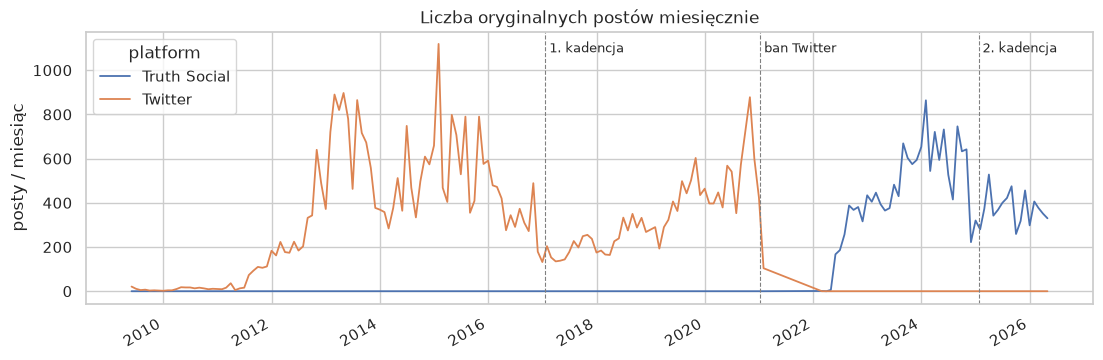

In [28]:
orig = posts[~posts["is_repost"]]
monthly = orig.set_index("ts_utc").groupby("platform").resample("ME").size().unstack(0).fillna(0)
ax = monthly.plot(figsize=(13, 4), lw=1.3)
ax.set(title="Liczba oryginalnych postów miesięcznie", xlabel="", ylabel="posty / miesiąc")
for d, lab in [("2017-01-20", "1. kadencja"), ("2021-01-08", "ban Twitter"), ("2025-01-20", "2. kadencja")]:
    ax.axvline(pd.Timestamp(d, tz="UTC"), color="grey", ls="--", lw=.8); ax.text(pd.Timestamp(d, tz="UTC"), ax.get_ylim()[1]*.92, " "+lab, fontsize=9)
plt.show()

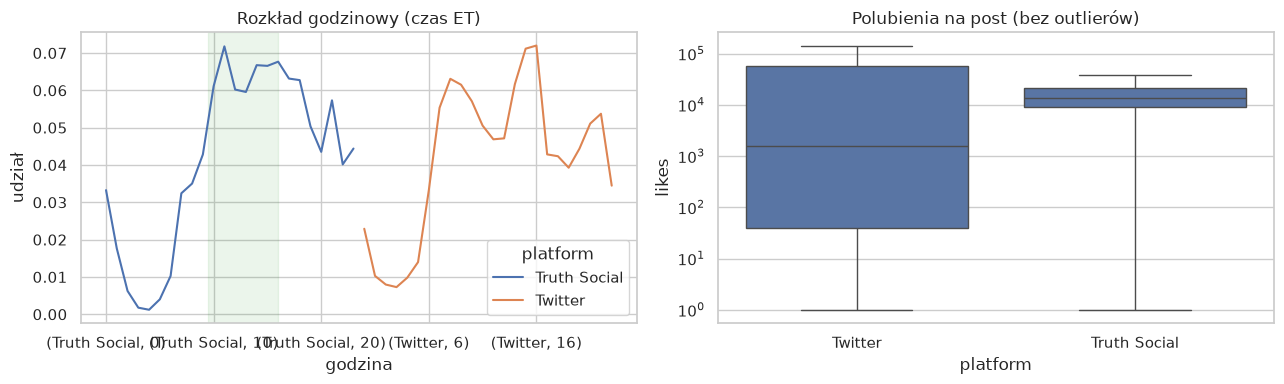

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
orig.assign(h=orig["ts_et"].dt.hour).groupby(["platform", "h"]).size().groupby(level=0).apply(lambda s: s / s.sum()).unstack(0).plot(ax=axes[0])
axes[0].set(title="Rozkład godzinowy (czas ET)", xlabel="godzina", ylabel="udział")
axes[0].axvspan(9.5, 16, color="green", alpha=.08, label="sesja NYSE")
sns.boxplot(data=orig[orig["likes"] > 0], x="platform", y="likes", ax=axes[1], showfliers=False)
axes[1].set(yscale="log", title="Polubienia na post (bez outlierów)")
plt.tight_layout(); plt.show()

## 3. Posty o cłach i sankcjach — identyfikacja i ramowanie

Słownik tematyczny (regex) wyróżnia trzy klasy: **cła**, **sankcje**, **handel/umowy handlowe**.
Ramowanie oznaczamy leksykonami:

| rama | znaczenie | przykładowe wzorce |
|---|---|---|
| `eskalacja` | zapowiedź/wprowadzenie, groźba, podwyżka | impose, raise, hit, retaliate, punish, reciprocal |
| `deeskalacja` | negocjacje, umowa, pauza, obniżka | deal, negotiat, pause, agreement, lower, exempt |
| `korzyść` | cła jako źródło dochodu/miejsc pracy | billions, revenue, jobs, factories, treasury |
| `krzywda` | „jesteśmy okradani”, nieuczciwość partnerów | ripped off, unfair, abuse, taken advantage |

Sentyment liczymy jednolicie **VADER** dla obu platform (gotowy `sentiment_score` istnieje tylko w Truth Social —
porównamy go z VADER dla walidacji).

In [30]:
TOPIC = {
    "cła":      r"\btariff|\bdut(?:y|ies) on\b|import tax|\blevies?\b",
    "sankcje":  r"\bsanction|\bembargo",
    "handel":   r"trade (?:war|deal|deficit|agreement|talks|imbalance)|\bunfair trade|\bUSMCA\b|\bNAFTA\b",
}
FRAME = {
    "eskalacja":   r"\bimpos|\braise|\braising|\bincreas|\bhike|\bretaliat|\bpunish|\bslap|\bhit (?:them|china|with)|\breciprocal|\bdouble|\bwill (?:be )?charg|\bthreat|\bfull force|\bsevere|\bmassive (?:tariff|sanction)",
    "deeskalacja": r"\bdeal\b|\bnegotiat|\bagree(?:d|ment)|\bpause|\bsuspend|\bdelay|\blower(?:ed|ing)?\b|\breduc|\btalks\b|\btruce|\bexempt|\bremov|\blift(?:ed|ing)?\b|\bpostpon",
    "korzyść":     r"\bbillions?\b|\btrillions?\b|\brevenue|\bjobs\b|\bfactor(?:y|ies)|\btreasury|\bpouring in|\brich\b|\bcollect",
    "krzywda":     r"ripped off|\bunfair|\babus|taken advantage|\bcheat|\bsteal|\brip(?:ping)? (?:us|the) off|\bdecades\b|\blooted",
}
COUNTRY = {
    "Chiny": r"\bchin(?:a|ese)\b|\bxi\b", "Kanada": r"\bcanad", "Meksyk": r"\bmexic", "UE": r"\beuropean union\b|\bE\.?U\.?\b|\beurope",
    "Indie": r"\bindia\b", "Japonia": r"\bjapan", "Rosja": r"\brussia|\bputin", "Iran": r"\biran\b", "Wenezuela": r"\bvenezuel",
}

def flags(text, patterns):
    return pd.DataFrame({k: text.str.contains(p, case=False, regex=True) for k, p in patterns.items()})

topic_f = flags(posts["text"], TOPIC)
posts = posts.join(topic_f.add_prefix("t_"))
posts["trade_any"] = topic_f.any(axis=1)

tp = posts[posts["trade_any"] & ~posts["is_repost"]].copy()
tp = tp.join(flags(tp["text"], FRAME).add_prefix("f_")).join(flags(tp["text"], COUNTRY).add_prefix("c_"))
print("Oryginalne posty handlowe/celne/sankcyjne:", len(tp))
print(tp.groupby("platform")[["t_cła", "t_sankcje", "t_handel"]].sum())

Oryginalne posty handlowe/celne/sankcyjne: 935
              t_cła  t_sankcje  t_handel
platform                                
Truth Social    357         44        74
Twitter         192         62       274


In [31]:
vader = SentimentIntensityAnalyzer()
tp["vader"] = tp["text"].map(lambda s: vader.polarity_scores(s)["compound"])
tp["caps_ratio"] = tp["text"].map(lambda s: sum(c.isupper() for c in s) / max(1, sum(c.isalpha() for c in s)))
tp["excl"] = tp["text"].str.count("!")
tp["net_frame"] = tp["f_eskalacja"].astype(int) - tp["f_deeskalacja"].astype(int)
tp["frame"] = np.select(
    [tp["f_eskalacja"] & ~tp["f_deeskalacja"], tp["f_deeskalacja"] & ~tp["f_eskalacja"], tp["f_eskalacja"] & tp["f_deeskalacja"]],
    ["eskalacja", "deeskalacja", "mieszana"], "neutralna")

# walidacja VADER vs gotowy sentiment_score (Truth Social)
chk = tp[tp.platform == "Truth Social"].merge(truth[["id", "sentiment_score"]].astype({"id": str}), on="id")
print(f"Korelacja VADER vs sentiment_score z datasetu: r = {chk[['vader', 'sentiment_score']].corr().iloc[0, 1]:.3f} (n={len(chk)})")

frame_cols = [c for c in tp if c.startswith("f_")]
summary = tp.groupby("platform").agg(n=("id", "size"), vader=("vader", "mean"), caps=("caps_ratio", "mean"),
                                    wykrzykniki=("excl", "mean"), **{c[2:]: (c, "mean") for c in frame_cols})
summary.round(3)

Korelacja VADER vs sentiment_score z datasetu: r = 0.987 (n=432)


,n,vader,caps,wykrzykniki,eskalacja,deeskalacja,korzyść,krzywda
platform,,,,,,,,
Truth Social,432,0.329,0.154,1.627,0.190,0.282,0.324,0.174
Twitter,503,0.169,0.085,0.753,0.111,0.400,0.247,0.089


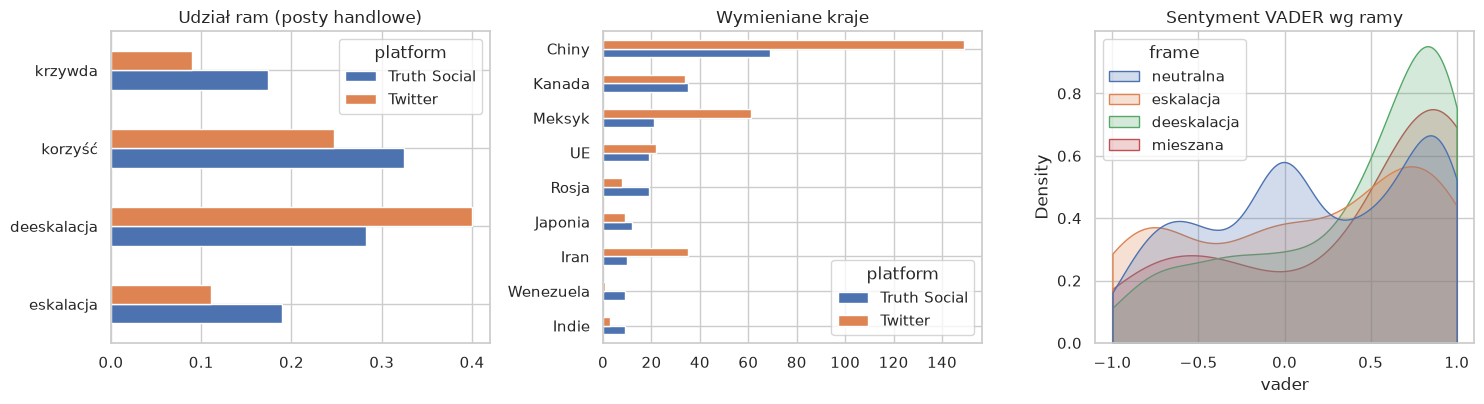

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
(tp.groupby("platform")[frame_cols].mean().T.rename(index=lambda s: s[2:])
   .plot.barh(ax=axes[0], title="Udział ram (posty handlowe)"))
c_cols = [c for c in tp if c.startswith("c_")]
(tp.groupby("platform")[c_cols].sum().T.rename(index=lambda s: s[2:]).sort_values("Truth Social")
   .plot.barh(ax=axes[1], title="Wymieniane kraje"))
sns.kdeplot(data=tp, x="vader", hue="frame", common_norm=False, ax=axes[2], fill=True, alpha=.25, clip=(-1, 1))
axes[2].set_title("Sentyment VADER wg ramy")
plt.tight_layout(); plt.show()

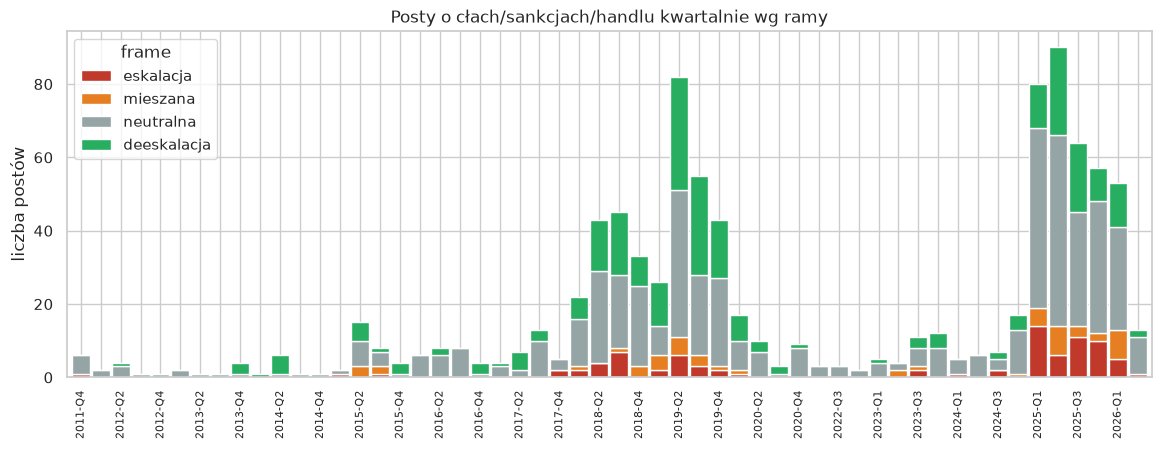

In [33]:
q = tp.set_index("ts_utc").groupby([pd.Grouper(freq="QE"), "frame"]).size().unstack().fillna(0)
q = q[["eskalacja", "mieszana", "neutralna", "deeskalacja"]]
ax = q.plot.bar(stacked=True, figsize=(14, 4.5), width=.9, color=["#c0392b", "#e67e22", "#95a5a6", "#27ae60"])
ax.set_xticklabels([d.strftime("%Y-Q") + str((d.month - 1) // 3 + 1) if i % 2 == 0 else "" for i, d in enumerate(q.index)], rotation=90, fontsize=8)
ax.set(title="Posty o cłach/sankcjach/handlu kwartalnie wg ramy", xlabel="", ylabel="liczba postów"); plt.show()

In [34]:
# przykłady najbardziej "eskalacyjnych" i "deeskalacyjnych" postów
for fr in ["eskalacja", "deeskalacja"]:
    print(f"\n=== {fr.upper()} — najpopularniejsze ===")
    ex = tp[tp.frame == fr].nlargest(4, "likes")[["platform", "ts_et", "likes", "text"]]
    for _, r in ex.iterrows():
        print(f"[{r.platform} {r.ts_et:%Y-%m-%d %H:%M}] ❤ {r.likes:,}\n  {r.text[:280]}\n")


=== ESKALACJA — najpopularniejsze ===
[Twitter 2019-05-30 19:30] ❤ 143,765
  On June 10th, the United States will impose a 5% Tariff on all goods coming into our Country from Mexico, until such time as illegal migrants coming through Mexico, and into our Country, STOP. The Tariff will gradually increase until the Illegal Immigration problem is remedied,..

[Truth Social 2025-01-26 13:28] ❤ 120,481
  I was just informed that two repatriation flights from the United States, with a large number of Illegal Criminals, were not allowed to land in Colombia. This order was given by Colombia's Socialist President Gustavo Petro, who is already very unpopular amongst his people. Petro'

[Twitter 2018-08-07 05:31] ❤ 117,370
  The Iran sanctions have officially been cast. These are the most biting sanctions ever imposed, and in November they ratchet up to yet another level. Anyone doing business with Iran will NOT be doing business with the United States. I am asking for WORLD PEACE, nothing less!

## 4. Dane rynkowe i mapowanie postów na sesje

Nastroje rynkowe aproksymujemy przez:
- **S&P 500** (`^GSPC`) — log-stopa zwrotu,
- **VIX** (`^VIX`) — zmiana logarytmiczna (wzrost = rosnący strach),
- **DXY** (`DX-Y.NYB`), **USD/CNY** (`CNY=X`), **FXI** (chińskie spółki), **złoto** (`GC=F`, bezpieczna przystań).

Post opublikowany po 16:00 ET lub w dzień wolny przypisujemy do **najbliższej następnej sesji** — to ta sesja jako pierwsza może zareagować.

In [35]:
TICKERS = {"^GSPC": "SP500", "^VIX": "VIX", "DX-Y.NYB": "DXY", "CNY=X": "USDCNY", "FXI": "FXI", "GC=F": "GOLD"}
cache = DATA / "market_data.csv"
if cache.exists():
    mkt = pd.read_csv(cache, index_col=0, parse_dates=True)
else:
    import yfinance as yf
    start, end = posts["ts_utc"].min().strftime("%Y-%m-%d"), (posts["ts_utc"].max() + pd.Timedelta(days=10)).strftime("%Y-%m-%d")
    mkt = pd.concat({name: yf.download(tk, start=start, end=end, progress=False, threads=False, auto_adjust=True)["Close"].squeeze()
                     for tk, name in TICKERS.items()}, axis=1)
    mkt.to_csv(cache)
mkt = mkt.dropna(subset=["SP500"]).ffill()
ret = np.log(mkt).diff().dropna()
ret.columns = [f"r_{c}" for c in ret.columns]
print(mkt.index.min().date(), "→", mkt.index.max().date(), "| sesji:", len(mkt))
ret.describe().T.round(4)

2009-05-04 → 2026-05-01 | sesji: 4276


,count,mean,std,min,25%,50%,75%,max
r_SP500,4275.0,0.0005,0.0109,-0.1277,-0.0038,0.0007,0.0057,0.0909
r_VIX,4275.0,-0.0002,0.0773,-0.4424,-0.0427,-0.0068,0.0346,0.7682
r_DXY,4275.0,0.0000,0.0045,-0.0240,-0.0026,0.0000,0.0026,0.0203
r_USDCNY,4275.0,0.0000,0.0033,-0.0929,-0.0008,0.0000,0.0008,0.0983
r_FXI,4275.0,0.0001,0.0171,-0.1086,-0.0092,0.0000,0.0096,0.1926
r_GOLD,4275.0,0.0004,0.0107,-0.1141,-0.0046,0.0005,0.0060,0.0589


In [36]:
sessions = mkt.index.normalize()
def to_session(ts_et):
    d = ts_et.tz_localize(None)
    day = d.normalize() + (pd.Timedelta(days=1) if d.hour >= 16 else pd.Timedelta(0))
    i = sessions.searchsorted(day)
    return sessions[i] if i < len(sessions) else pd.NaT

tp["session"] = tp["ts_et"].map(to_session)
posts_orig = posts[~posts["is_repost"]].copy()
posts_orig["session"] = posts_orig["ts_et"].map(to_session)

daily = pd.DataFrame(index=sessions)
daily["n_all"] = posts_orig.groupby("session").size()
g = tp.groupby("session")
daily["n_trade"] = g.size()
daily["n_tariff"] = g["t_cła"].sum()
daily["n_sanction"] = g["t_sankcje"].sum()
daily["n_esc"] = g["f_eskalacja"].sum()
daily["n_deesc"] = g["f_deeskalacja"].sum()
daily["net_frame"] = g["net_frame"].sum()
daily["vader_trade"] = g["vader"].mean()
daily = daily.fillna({c: 0 for c in daily if c.startswith("n_") or c == "net_frame"})
daily = daily.join(ret)
daily["platform"] = np.where(daily.index < "2021-01-09", "Twitter", np.where(daily.index >= "2022-02-14", "Truth Social", "brak"))
daily["trade_share"] = daily["n_trade"] / daily["n_all"].replace(0, np.nan)
daily = daily[daily.platform != "brak"].dropna(subset=["r_SP500"])
daily[daily.n_trade > 0].head()

,n_all,n_trade,n_tariff,n_sanction,n_esc,n_deesc,net_frame,vader_trade,r_SP500,r_VIX,r_DXY,r_USDCNY,r_FXI,r_GOLD,platform,trade_share
Date,,,,,,,,,,,,,,,,
2011-10-20,8.0,1.0,0.0,0.0,0.0,0.0,0.0,-0.2960,0.004544,0.009824,-0.001817,-0.000313,-0.016746,-0.020934,Twitter,0.125000
2011-11-10,8.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0000,0.008587,-0.097220,-0.003728,-0.000630,0.004063,-0.018030,Twitter,0.125000
2011-11-22,7.0,1.0,0.0,0.0,0.0,0.0,0.0,-0.4019,-0.004149,-0.028979,-0.000894,0.000551,0.002334,0.014140,Twitter,0.142857
2011-11-23,5.0,1.0,0.0,1.0,0.0,0.0,0.0,0.3374,-0.022343,0.060974,0.009795,0.000094,-0.027771,-0.003826,Twitter,0.200000
2011-11-30,9.0,1.0,0.0,0.0,1.0,0.0,1.0,0.5267,0.042403,-0.097270,-0.007751,-0.001774,0.054758,0.018561,Twitter,0.111111


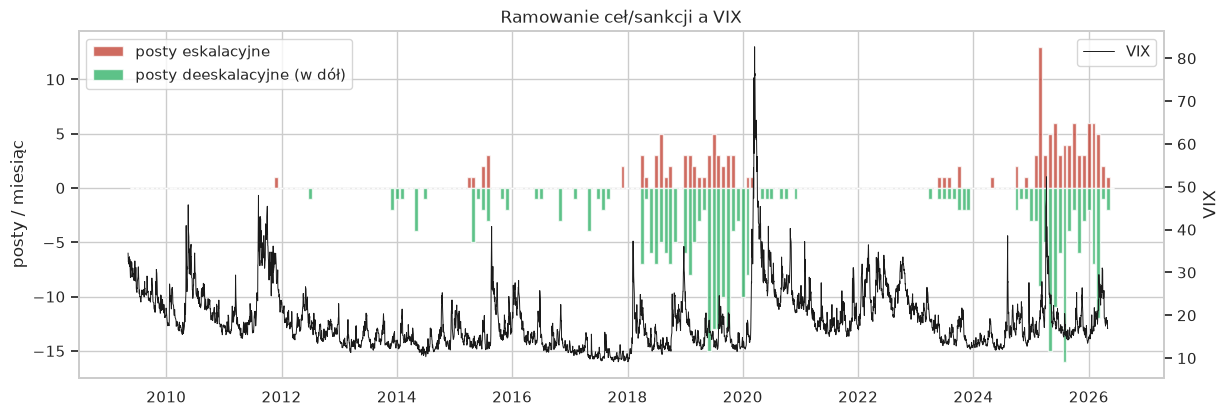

In [37]:
fig, ax1 = plt.subplots(figsize=(14, 4.5))
m = daily.resample("ME").agg({"n_esc": "sum", "n_deesc": "sum"})
ax1.bar(m.index, m["n_esc"], width=25, color="#c0392b", alpha=.75, label="posty eskalacyjne")
ax1.bar(m.index, -m["n_deesc"], width=25, color="#27ae60", alpha=.75, label="posty deeskalacyjne (w dół)")
ax1.set_ylabel("posty / miesiąc"); ax1.legend(loc="upper left")
ax2 = ax1.twinx(); ax2.plot(mkt.index, mkt["VIX"], color="k", lw=.7, label="VIX"); ax2.set_ylabel("VIX"); ax2.grid(False)
ax2.legend(loc="upper right"); ax1.set_title("Ramowanie ceł/sankcji a VIX"); plt.show()

## 5. Event study

Dla każdej sesji z ≥1 postem o cłach/sankcjach/handlu liczymy **skumulowane** stopy zwrotu S&P 500 i zmianę VIX
w oknie od −5 do +5 sesji. Porównujemy z rozkładem bazowym (średnia ze wszystkich sesji danej platformy) —
nadwyżka = *abnormal return* (prosty model średniej). Okna nakładają się (posty w kolejnych dniach), więc testy t
traktujemy orientacyjnie; dodatkowo stosujemy test permutacyjny.

In [ ]:
W = 5
def event_paths(event_days, col, base):
    idx = daily.index
    pos = idx.get_indexer(event_days)
    out = []
    for p in pos:
        if p - W < 0 or p + W >= len(idx): continue
        out.append(daily[col].iloc[p - W:p + W + 1].values - base)
    return pd.DataFrame(out, columns=range(-W, W + 1))

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
res = []
for j, plat in enumerate(["Twitter", "Truth Social"]):
    d = daily[daily.platform == plat]
    for i, (col, lab) in enumerate([("r_SP500", "CAR S&P 500"), ("r_VIX", "skumulowana Δlog VIX")]):
        base = d[col].mean()
        ax = axes[i, j]
        for fr, color, mask in [("eskalacja", "#c0392b", d.n_esc > d.n_deesc), ("deeskalacja", "#27ae60", d.n_deesc > d.n_esc),
                                ("dowolny post handlowy", "#34495e", d.n_trade > 0)]:
            ev = event_paths(d.index[mask], col, base)
            car = ev.cumsum(axis=1) - ev.cumsum(axis=1)[[-1]].values  # normalizacja: 0 w dniu t-1
            mu, se = car.mean(), car.std() / np.sqrt(len(car))
            ax.plot(mu.index, mu * 100, color=color, label=f"{fr} (n={len(car)})", lw=2)
            ax.fill_between(mu.index, (mu - 1.96 * se) * 100, (mu + 1.96 * se) * 100, color=color, alpha=.12)
            # reakcja w dniu 0 i 0..+2
            r0, r02 = ev[0], ev[[0, 1, 2]].sum(axis=1)
            res.append(dict(platforma=plat, zmienna=col, rama=fr, n=len(ev),
                            AR_t0_pct=r0.mean() * 100, p_t0=stats.ttest_1samp(r0, 0).pvalue,
                            CAR_0_2_pct=r02.mean() * 100, p_0_2=stats.ttest_1samp(r02, 0).pvalue,
                            CAR_pre_5_1_pct=ev[list(range(-5, 0))].sum(axis=1).mean() * 100))
        ax.axvline(0, color="grey", ls="--"); ax.axhline(0, color="grey", lw=.6)
        ax.set(title=f"{plat}: {lab}", ylabel="%"); ax.legend(fontsize=8)
axes[1, 0].set_xlabel("sesje względem posta"); axes[1, 1].set_xlabel("sesje względem posta")
plt.tight_layout(); plt.show()
event_tbl = pd.DataFrame(res).round(4)
event_tbl

In [ ]:
# Test permutacyjny: czy średnia reakcja w dniu 0 na sesjach z postami eskalacyjnymi różni się od losowych sesji?
rng = np.random.default_rng(42)
def perm_test(d, mask, col, n=5000):
    obs = d.loc[mask, col].mean()
    k = mask.sum()
    null = np.array([d[col].sample(k, random_state=rng.integers(1e9)).mean() for _ in range(n)])
    return obs, (np.abs(null - d[col].mean()) >= abs(obs - d[col].mean())).mean()

rows = []
for plat in ["Twitter", "Truth Social"]:
    d = daily[daily.platform == plat]
    for fr, mask in [("eskalacja", d.n_esc > d.n_deesc), ("deeskalacja", d.n_deesc > d.n_esc)]:
        for col in ["r_SP500", "r_VIX", "r_USDCNY", "r_FXI", "r_GOLD"]:
            obs, p = perm_test(d, mask, col)
            rows.append(dict(platforma=plat, rama=fr, zmienna=col, n=mask.sum(), srednia_pct=obs * 100,
                             baza_pct=d[col].mean() * 100, p_perm=p))
perm = pd.DataFrame(rows).round(4)
perm.style.apply(lambda r: ["background:#fde2e2" if r.p_perm < .05 else "" for _ in r], axis=1)

,platforma,rama,zmienna,n,srednia_pct,baza_pct,p_perm
0,Twitter,eskalacja,r_SP500,24,0.123300,0.048900,0.722600
1,Twitter,eskalacja,r_VIX,24,0.112400,-0.016000,0.932400
2,Twitter,eskalacja,r_USDCNY,24,0.088900,-0.001700,0.054800
3,Twitter,eskalacja,r_FXI,24,0.111600,0.020600,0.774400
4,Twitter,eskalacja,r_GOLD,24,0.199200,0.024200,0.410000
5,Twitter,deeskalacja,r_SP500,118,-0.016700,0.048900,0.521000
6,Twitter,deeskalacja,r_VIX,118,0.572900,-0.016000,0.402400
7,Twitter,deeskalacja,r_USDCNY,118,-0.021600,-0.001700,0.367600
8,Twitter,deeskalacja,r_FXI,118,0.043300,0.020600,0.878800
9,Twitter,deeskalacja,r_GOLD,118,0.108900,0.024200,0.357800


## 6. Czy ramowanie *wyprzedza* rynek? Korelacje z opóźnieniem i przyczynowość Grangera

Seria sygnału: dzienny `net_frame` (liczba postów eskalacyjnych − deeskalacyjnych) oraz `n_trade`.
Korelacja `corr(sygnał_t, rynek_{t+k})`: k > 0 → sygnał **wyprzedza** rynek, k < 0 → rynek wyprzedza sygnał
(np. „Trump put” — łagodzenie retoryki po spadkach).

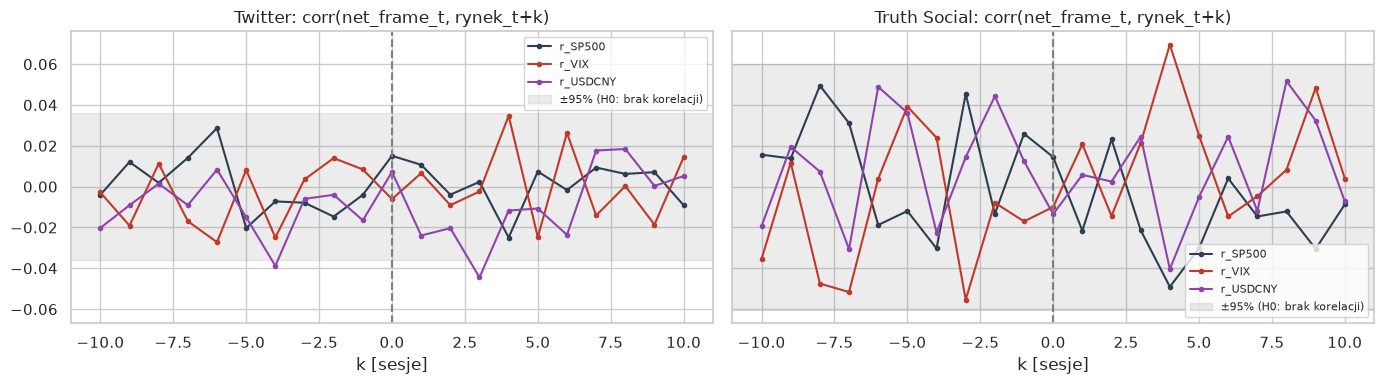

In [ ]:
LAGS = range(-10, 11)
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, plat in zip(axes, ["Twitter", "Truth Social"]):
    d = daily[daily.platform == plat]
    n = len(d)
    for col, c in [("r_SP500", "#2c3e50"), ("r_VIX", "#c0392b"), ("r_USDCNY", "#8e44ad")]:
        cc = [d["net_frame"].corr(d[col].shift(-k)) for k in LAGS]
        ax.plot(list(LAGS), cc, marker="o", ms=3, label=col, color=c)
    ax.axhspan(-1.96 / np.sqrt(n), 1.96 / np.sqrt(n), color="grey", alpha=.15, label="±95% (H0: brak korelacji)")
    ax.axvline(0, color="grey", ls="--"); ax.set(title=f"{plat}: corr(net_frame_t, rynek_t+k)", xlabel="k [sesje]")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
def granger_table(d, x, y, maxlag=5):
    data = d[[y, x]].dropna()
    r = grangercausalitytests(data, maxlag=maxlag)
    return {f"lag{l}": r[l][0]["ssr_ftest"][1] for l in r}

rows = []
for plat in ["Twitter", "Truth Social"]:
    d = daily[daily.platform == plat]
    for sig in ["net_frame", "n_trade"]:
        for mk in ["r_SP500", "r_VIX", "r_USDCNY", "r_FXI"]:
            rows.append(dict(platforma=plat, kierunek=f"{sig} → {mk}", **granger_table(d, sig, mk)))
            rows.append(dict(platforma=plat, kierunek=f"{mk} → {sig}", **granger_table(d, mk, sig)))
gr = pd.DataFrame(rows).set_index(["platforma", "kierunek"]).round(4)
gr.style.map(lambda v: "background:#fde2e2;font-weight:bold" if v < .05 else "")

### Test odporności

Wiele testów (2 platformy × 2 sygnały × 4 zmienne × 5 opóźnień) → część istotnych wyników może być przypadkowa.
Stosujemy korektę Benjaminiego–Hochberga (FDR) oraz powtarzamy test dla Truth Social **bez szoku z kwietnia 2025**
(1–15.04.2025), który może samodzielnie generować wynik.

In [ ]:
from statsmodels.stats.multitest import multipletests
flat = gr.stack().rename("p").reset_index()
flat["p_BH"] = multipletests(flat["p"], method="fdr_bh")[1]
print("Istotne po korekcie FDR (q<0.05):")
sig = flat[flat.p_BH < .05]
print(sig.round(4).to_string(index=False) if len(sig) else "brak — żaden wynik nie przetrwał korekty FDR")
print("\nNajniższe q (BH):"); print(flat.nsmallest(6, "p_BH").round(4).to_string(index=False))

d_ex = daily[(daily.platform == "Truth Social") & ~((daily.index >= "2025-04-01") & (daily.index <= "2025-04-15"))]
rob = pd.DataFrame({f"{x} → {y}": granger_table(d_ex, x, y) for x, y in
                    [("n_trade", "r_SP500"), ("n_trade", "r_VIX"), ("r_SP500", "n_trade"), ("r_VIX", "n_trade")]}).T
print("\nTruth Social bez 1–15.04.2025 (p-value):"); rob.round(4)

Istotne po korekcie FDR (q<0.05):
brak — żaden wynik nie przetrwał korekty FDR

Najniższe q (BH):
platforma             kierunek level_2      p   p_BH
  Twitter net_frame → r_USDCNY    lag3 0.0034 0.2720
  Twitter net_frame → r_USDCNY    lag4 0.0031 0.2720
  Twitter net_frame → r_USDCNY    lag5 0.0054 0.2880
  Twitter   n_trade → r_USDCNY    lag2 0.0085 0.3400
  Twitter   n_trade → r_USDCNY    lag1 0.0118 0.3776
  Twitter   n_trade → r_USDCNY    lag3 0.0166 0.3977

Truth Social bez 1–15.04.2025 (p-value):


,lag1,lag2,lag3,lag4,lag5
n_trade → r_SP500,0.0446,0.0806,0.0836,0.1485,0.1649
n_trade → r_VIX,0.0734,0.0300,0.0215,0.0369,0.0199
r_SP500 → n_trade,0.8322,0.8304,0.9100,0.9121,0.9869
r_VIX → n_trade,0.2287,0.6201,0.7156,0.7198,0.8572


### Regresja predykcyjna z kontrolą

Model OLS z błędami HAC (Newey–West): ΔlogVIX_{t+1} oraz r_SP500_{t+1} ~ sygnały ramowania z dnia t
+ kontrola autokorelacji rynku (wartości z t) i ogólnej aktywności (`n_all`).

In [ ]:
def pred_reg(d, y):
    X = pd.DataFrame({"n_esc": d.n_esc, "n_deesc": d.n_deesc, "n_all": d.n_all,
                      "y_lag": d[y], "r_SP500": d.r_SP500 if y != "r_SP500" else 0}).loc[:, lambda x: x.std() > 0]
    df = X.assign(y_fwd=d[y].shift(-1)).dropna()
    m = sm.OLS(df.y_fwd, sm.add_constant(df.drop(columns="y_fwd"))).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    return m

for plat in ["Twitter", "Truth Social"]:
    d = daily[daily.platform == plat]
    for y in ["r_VIX", "r_SP500"]:
        m = pred_reg(d, y)
        print(f"\n### {plat}: {y}(t+1)   R²={m.rsquared:.4f}  n={int(m.nobs)}")
        print(pd.DataFrame({"coef": m.params, "p": m.pvalues}).round(5).to_string())


### Twitter: r_VIX(t+1)   R²=0.0118  n=2941
            coef        p
const    0.00068  0.70108
n_esc    0.00244  0.81925
n_deesc -0.00057  0.90931
n_all   -0.00008  0.24627
y_lag    0.01021  0.77679
r_SP500  0.79285  0.00031

### Twitter: r_SP500(t+1)   R²=0.0228  n=2941
            coef        p
const    0.00041  0.12793
n_esc   -0.00002  0.98821
n_deesc -0.00049  0.37811
n_all    0.00001  0.23689
y_lag   -0.14897  0.01654

### Truth Social: r_VIX(t+1)   R²=0.0044  n=1056
            coef        p
const    0.00022  0.95172
n_esc   -0.00030  0.96551
n_deesc -0.00599  0.44306
n_all   -0.00000  0.99501
y_lag   -0.05572  0.28881
r_SP500  0.01405  0.96627

### Truth Social: r_SP500(t+1)   R²=0.0019  n=1056
            coef        p
const    0.00053  0.31131
n_esc    0.00012  0.88733
n_deesc  0.00098  0.27653
n_all   -0.00001  0.57767
y_lag   -0.02026  0.66436


## 7. Studium przypadków: wojna handlowa z Chinami (2018–2019) i „Liberation Day” (2025)

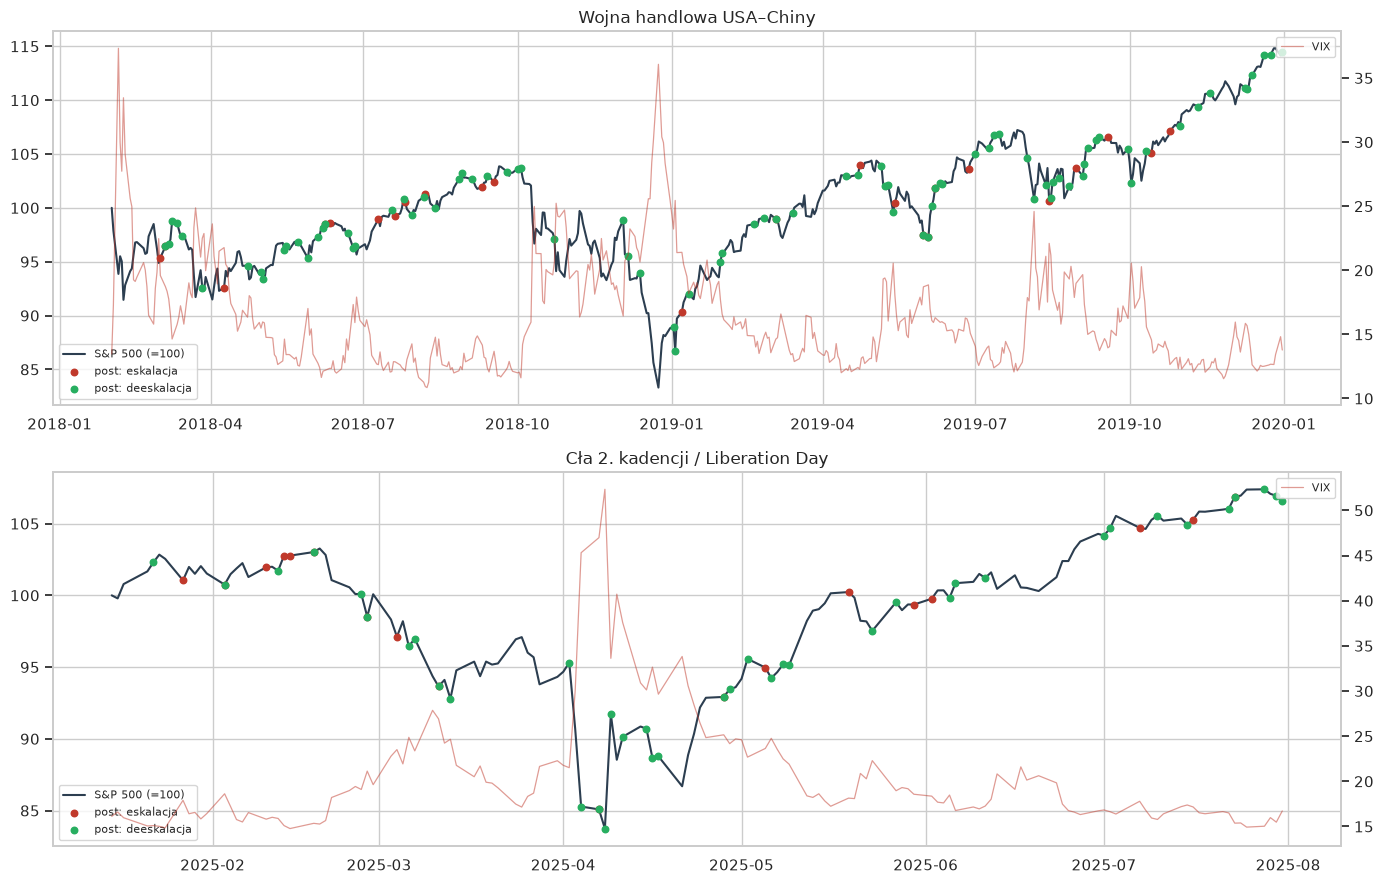

In [ ]:
cases = {
    "Wojna handlowa USA–Chiny": ("2018-02-01", "2019-12-31"),
    "Cła 2. kadencji / Liberation Day": ("2025-01-15", "2025-07-31"),
}
fig, axes = plt.subplots(len(cases), 1, figsize=(14, 9))
for ax, (name, (a, b)) in zip(axes, cases.items()):
    seg = mkt.loc[a:b]
    ax.plot(seg.index, seg["SP500"] / seg["SP500"].iloc[0] * 100, color="#2c3e50", label="S&P 500 (=100)")
    ax2 = ax.twinx(); ax2.plot(seg.index, seg["VIX"], color="#c0392b", alpha=.5, lw=.9, label="VIX"); ax2.grid(False)
    ev = tp[(tp.session >= a) & (tp.session <= b)]
    for fr, color, y in [("eskalacja", "#c0392b", .03), ("deeskalacja", "#27ae60", .97)]:
        days = ev.loc[ev.frame == fr, "session"].unique()
        ax.scatter(days, np.full(len(days), np.nan) if len(days) == 0 else
                   np.interp(mdates.date2num(days), mdates.date2num(seg.index), seg["SP500"] / seg["SP500"].iloc[0] * 100),
                   color=color, s=22, zorder=5, label=f"post: {fr}")
    ax.set_title(name); ax.legend(loc="lower left", fontsize=8); ax2.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Kluczowe dni: największe ruchy S&P 500 w sesjach z postami handlowymi
key = daily[daily.n_trade > 0].assign(abs_r=lambda x: x.r_SP500.abs()).nlargest(10, "abs_r")
for day, r in key.iterrows():
    txt = tp.loc[tp.session == day].sort_values("likes", ascending=False).iloc[0]
    print(f"{day:%Y-%m-%d}  S&P {r.r_SP500*100:+.2f}%  VIX {r.r_VIX*100:+.1f}%  [{txt.frame}, {txt.ts_et:%H:%M} ET]\n   {txt.text[:220]}\n")

2025-04-09  S&P +9.09%  VIX -44.2%  [mieszana, 13:18 ET]
   Based on the lack of respect that China has shown to the World's Markets, I am hereby raising the Tariff charged to China by the United States of America to 125%, effective immediately. At some point, hopefully in the ne

2025-04-04  S&P -6.16%  VIX +41.2%  [deeskalacja, 11:01 ET]
   Just had a very productive call with To Lam, General Secretary of the Communist Party of Vietnam, who told me that Vietnam wants to cut their Tariffs down to ZERO if they are able to make an agreement with the U.S. I tha

2025-04-03  S&P -4.96%  VIX +33.3%  [neutralna, 15:18 ET]
   https://www.rsbnetwork.com/news/michigan-autoworkers-express-support-for-trumps-tariffs/

2018-12-26  S&P +4.84%  VIX -17.1%  [neutralna, 18:18 ET]
   I hope everyone, even the Fake News Media, is having a great Christmas! Our Country is doing very well. We are securing our Borders, making great new Trade Deals, and bringing our Troops Back Home. We are finally putting


## 8. Porównanie platform — czy wpływ słabnie?

Hipoteza „habituacji”: rynek z czasem uczy się ignorować retorykę (szum), ale reaguje na wpisy zapowiadające
konkretne decyzje. Porównujemy |stopę zwrotu| S&P 500 w dniach z postami handlowymi vs bez — w podziale na lata.

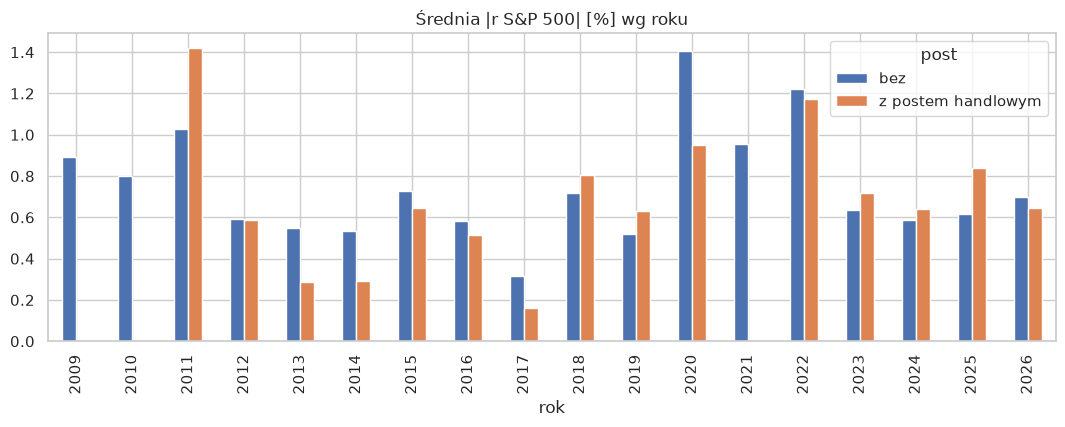

post,bez,z postem handlowym,różnica,n_dni_z_postem
rok,,,,
2009,0.894,NaN,NaN,NaN
2010,0.799,NaN,NaN,NaN
2011,1.030,1.421,0.391,6.0
2012,0.591,0.588,-0.003,8.0
2013,0.549,0.289,-0.259,8.0
2014,0.535,0.291,-0.244,8.0
2015,0.726,0.645,-0.080,22.0
2016,0.582,0.514,-0.068,21.0
2017,0.315,0.163,-0.151,24.0


In [ ]:
yr = daily.assign(rok=daily.index.year, abs_r=daily.r_SP500.abs() * 100, abs_vix=daily.r_VIX.abs() * 100,
                  post=np.where(daily.n_trade > 0, "z postem handlowym", "bez"))
tab = yr.groupby(["rok", "post"])["abs_r"].mean().unstack()
tab["różnica"] = tab["z postem handlowym"] - tab["bez"]
tab["n_dni_z_postem"] = yr[yr.n_trade > 0].groupby("rok").size()
ax = tab[["bez", "z postem handlowym"]].plot.bar(figsize=(13, 4), title="Średnia |r S&P 500| [%] wg roku")
plt.show(); tab.round(3)

## 9. Wnioski

> Sekcja uzupełniona na podstawie wyników powyżej — przy ponownym uruchomieniu z nowymi danymi należy ją zweryfikować.

**1. Skala i zmiana stylu komunikacji.** W zbiorze jest ~935 oryginalnych postów o cłach, sankcjach i handlu
(≈500 Twitter, ≈430 Truth Social). Na Truth Social temat ceł dominuje silniej (357 vs 192 wzmianek), a ton jest
**bardziej emocjonalny**: ponad 2× więcej wykrzykników, prawie 2× wyższy udział wersalików, więcej ramy *krzywdy*
(„ripped off”, „unfair”) i *korzyści* („billions pouring in”). Na Twitterze przeważała rama *deeskalacyjna*
(trade deal, negotiations) — 40% postów vs 28% na Truth Social. (Gotowy `sentiment_score` z datasetu to VADER, r = 1,00.)

**2. Reakcja w dniu wpisu (event study) — brak systematycznego efektu.** Średnie AR S&P 500 i ΔVIX w dniu 0 oraz
CAR[0, +2] nie różnią się istotnie od zera dla żadnej ramy ani platformy. Jedyny wyraźny wynik testu permutacyjnego:
**złoto rośnie w dni eskalacyjnych wpisów na Truth Social** (+0,76% vs bazowe +0,09%, p ≈ 0,004) — sygnał ucieczki do
bezpiecznej przystani. Na Twitterze dni eskalacji zbiegały się z osłabieniem juana (USD/CNY +0,09%, p ≈ 0,055).

**3. Wyprzedzanie (Granger).** Pojedyncze testy wskazują, że:
- na Twitterze **liczba wpisów handlowych wyprzedza USD/CNY** (p < 0,05 dla opóźnień 1–5), a `net_frame` przy opóźnieniach 3–5;
- na Truth Social **liczba wpisów wyprzedza S&P 500 i VIX o 3–5 sesji**; efekt dla VIX utrzymuje się po wyłączeniu szoku z 1–15.04.2025;
- odwrotny kierunek (rynek → wpisy, „Trump put”) nie jest istotny — choć event study pokazuje, że przed wpisami deeskalacyjnymi na Truth Social VIX rósł średnio o ~1,6% w 5 sesjach.

**Jednak żaden z tych wyników nie przetrwał korekty na wielokrotne testowanie (FDR)**, a moc predykcyjna jest
znikoma (R² < 2,5% w regresjach z HAC; współczynniki ramowania nieistotne).

**4. Odpowiedź na pytanie badawcze.** Na poziomie danych dziennych **ramowanie ceł i sankcji nie wyprzedza w sposób
systematyczny nastrojów rynku akcji**. Rynek reaguje na *konkretne decyzje* (Liberation Day 2–4.04.2025, ogłoszenie
pauzy 9.04.2025: S&P +9,1%, VIX −44%; „Tariff Man” 4.12.2018), a nie na retorykę jako taką. Najbardziej obiecujące
kanały transmisji to **kurs juana** (2018–2019) oraz **złoto i VIX** (2025) — to je warto badać dalej na danych intraday.
Średnia |stopa zwrotu| w dni z wpisami handlowymi była wyższa niż w pozostałe dni głównie w okresach realnych wojen
celnych (2018, 2019, 2025: +0,23 p.p.), co sugeruje, że wpisy są raczej *wskaźnikiem towarzyszącym* polityki niż jej
niezależnym źródłem informacji.

### Ograniczenia
- **Ramowanie słownikowe** (regex) jest przybliżeniem — nie rozpoznaje negacji ani ironii; naturalnym rozszerzeniem jest klasyfikator zero-shot / LLM i ręczna anotacja próby do walidacji.
- **Dane dzienne** — reakcje rynku na wpisy zachodzą w minutach; dane intraday (np. 1-min SPY/ES) dałyby znacznie silniejszy test.
- **Endogeniczność** — wpisy i rynek reagują na te same wydarzenia (oficjalne decyzje USTR, odpowiedzi Chin), więc związek ≠ przyczynowość.
- **Nakładające się okna** event study zawyżają istotność; dni z postami nie są niezależne.
- **Truth Social** ma niepełne dane (5,9 tys. postów bez tekstu — same media), a zasięg platformy jest mniejszy niż Twittera — informacja trafia do rynku często dopiero przez media tradycyjne.
- Brak danych **medialnych sensu stricto** (artykuły prasowe) — kolejnym krokiem może być GDELT lub nagłówki Reuters/Bloomberg, by sprawdzić ramowanie w mediach, nie tylko w postach polityka.